In [1]:
import os
import io
import zipfile
import warnings
import urllib.request
from pathlib import Path

import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

warnings.filterwarnings("ignore")

# Create project directories
for folder in ["data", "outputs"]:
    Path(folder).mkdir(parents=True, exist_ok=True)

# Write centralized configuration file for reproducibility
config_yaml = """
project:
  name: "diabetic_readmission_mnar_calibration_audit"
  random_state: 42

data:
  uci_zip_url: "https://archive.ics.uci.edu/ml/machine-learning-databases/00296/dataset_diabetes.zip"
  local_csv: "data/dataset_diabetes/diabetic_data.csv"
  expired_hospice_ids: [11, 13, 14, 19, 20, 21]
  zero_variance_cols: ["examide", "citoglipton"]
  mnar_cols: ["weight", "max_glu_serum", "A1Cresult", "payer_code", "medical_specialty"]
  min_category_freq: 250

validation:
  n_splits: 5
  calibration_test_size: 0.20
  ece_bins: 10
  clinical_decision_threshold: 0.15

models:
  logistic_regression:
    C: 1.0
    max_iter: 1000
  random_forest:
    n_estimators: 150
    max_depth: 12
    min_samples_leaf: 20
    n_jobs: -1
  hist_gbdt:
    max_iter: 200
    max_depth: 8
    learning_rate: 0.05
    min_samples_leaf: 30
"""

with open("config.yaml", "w") as f:
    f.write(config_yaml.strip())

with open("config.yaml", "r") as f:
    CFG = yaml.safe_load(f)

SEED = CFG["project"]["random_state"]
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
print("Configuration loaded from config.yaml.")

Configuration loaded from config.yaml.


In [2]:
def load_raw_diabetes_data(cfg: dict) -> pd.DataFrame:
    csv_path = Path(cfg["data"]["local_csv"])
    if not csv_path.exists():
        print("Downloading Diabetes 130-US Hospitals dataset from UCI...")
        req = urllib.request.urlopen(cfg["data"]["uci_zip_url"])
        with zipfile.ZipFile(io.BytesIO(req.read())) as zf:
            zf.extractall("data")
    df = pd.read_csv(
        csv_path,
        keep_default_na=False,
        na_values=["", "?", "None", "NA", "NaN", "null", "Unknown/Invalid"],
        low_memory=False,
    )
    return df


def map_icd9_group(code) -> object:
    """Map ICD-9 diagnosis codes into Strack et al. (2014) clinical disease categories."""
    if pd.isna(code):
        return np.nan
    s = str(code).strip()
    if s.startswith(("V", "E")):
        return "Other"
    try:
        val = float(s)
    except ValueError:
        return "Other"

    if (390 <= val <= 459) or val == 785:
        return "Circulatory"
    elif (460 <= val <= 519) or val == 786:
        return "Respiratory"
    elif (520 <= val <= 579) or val == 787:
        return "Digestive"
    elif 250 <= val < 251:
        return "Diabetes"
    elif 800 <= val <= 999:
        return "Injury"
    elif 710 <= val <= 739:
        return "Musculoskeletal"
    elif (580 <= val <= 629) or val == 788:
        return "Genitourinary"
    elif 140 <= val <= 239:
        return "Neoplasms"
    else:
        return "Other"


def prepare_clinical_cohort(df_raw: pd.DataFrame, cfg: dict) -> pd.DataFrame:
    df = df_raw.copy()
    initial_n = len(df)
    initial_patients = df["patient_nbr"].nunique()

    # 1. Exclude expired or hospice encounters (cannot be readmitted within 30 days)
    df = df[~df["discharge_disposition_id"].isin(cfg["data"]["expired_hospice_ids"])].copy()

    # 2. Drop zero-variance medication columns
    df.drop(columns=cfg["data"]["zero_variance_cols"], errors="ignore", inplace=True)

    # 3. Define binary 30-day readmission target
    df["target"] = (df["readmitted"] == "<30").astype(int)

    # 4. Convert age brackets to ordinal midpoints (keep original bracket for subgroup audits)
    age_map = {
        "[0-10)": 5, "[10-20)": 15, "[20-30)": 25, "[30-40)": 35, "[40-50)": 45,
        "[50-60)": 55, "[60-70)": 65, "[70-80)": 75, "[80-90)": 85, "[90-100)": 95,
    }
    df["age_midpoint"] = df["age"].map(age_map)

    # 5. Consolidate ICD-9 diagnoses into 9 clinical categories
    for col in ["diag_1", "diag_2", "diag_3"]:
        df[f"{col}_grp"] = df[col].apply(map_icd9_group)

    # 6. Engineer clinical medication burden & utilization features
    med_cols = [
        "metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride",
        "acetohexamide", "glipizide", "glyburide", "tolbutamide", "pioglitazone",
        "rosiglitazone", "acarbose", "miglitol", "troglitazone", "tolazamide",
        "insulin", "glyburide-metformin", "glipizide-metformin",
        "glimepiride-pioglitazone", "metformin-rosiglitazone", "metformin-pioglitazone",
    ]
    med_cols = [c for c in med_cols if c in df.columns]
    df["num_med_changes"] = df[med_cols].isin(["Up", "Down"]).sum(axis=1)
    df["num_active_meds"] = (df[med_cols] != "No").sum(axis=1)
    df["total_prior_visits"] = (
        df["number_outpatient"] + df["number_emergency"] + df["number_inpatient"]
    )

    # 7. Cast administrative IDs to strings so encoders treat them as categorical
    for id_col in ["admission_type_id", "discharge_disposition_id", "admission_source_id"]:
        df[id_col] = df[id_col].astype(str)

    # 8. Group broad age buckets for clean subgroup calibration audits
    df["age_group"] = pd.cut(
        df["age_midpoint"],
        bins=[0, 49, 69, 100],
        labels=["<50", "50-69", "70+"],
    ).astype(str)

    print(f"Raw encounters: {initial_n:,} ({initial_patients:,} unique patients)")
    print(f"Filtered cohort: {len(df):,} encounters ({df['patient_nbr'].nunique():,} unique patients)")
    print(f"Patients with >1 encounter (leakage risk): {(df.groupby('patient_nbr').size() > 1).sum():,}")
    print(f"30-day readmission prevalence: {df['target'].mean() * 100:.2f}%")
    return df


df_raw = load_raw_diabetes_data(CFG)
df = prepare_clinical_cohort(df_raw, CFG)

Raw encounters: 101,766 (71,518 unique patients)
Filtered cohort: 99,343 encounters (69,990 unique patients)
Patients with >1 encounter (leakage risk): 16,341
30-day readmission prevalence: 11.39%


,Feature,Missing_%,Readmit_%_Measured,Readmit_%_Missing,Delta_%,Chi2_p_value
0,weight,96.85,11.39,11.39,-0.00,1.000000e+00
1,max_glu_serum,94.81,12.75,11.31,-1.44,1.681451e-03
2,A1Cresult,83.05,9.94,11.68,1.75,8.719126e-11
4,medical_specialty,48.94,10.96,11.83,0.87,1.634978e-05
3,payer_code,39.66,11.19,11.69,0.50,1.552347e-02


,Count,Readmit_%,A1C_Missing_%,Payer_Missing_%
race_clean,,,,
AfricanAmerican,18772,11.45,81.44,48.33
Asian,628,10.35,78.98,41.56
Caucasian,74220,11.53,83.82,37.58
Hispanic,2017,10.51,75.76,48.83
Missing,2234,8.42,81.20,23.77
Other,1472,9.78,79.55,44.43


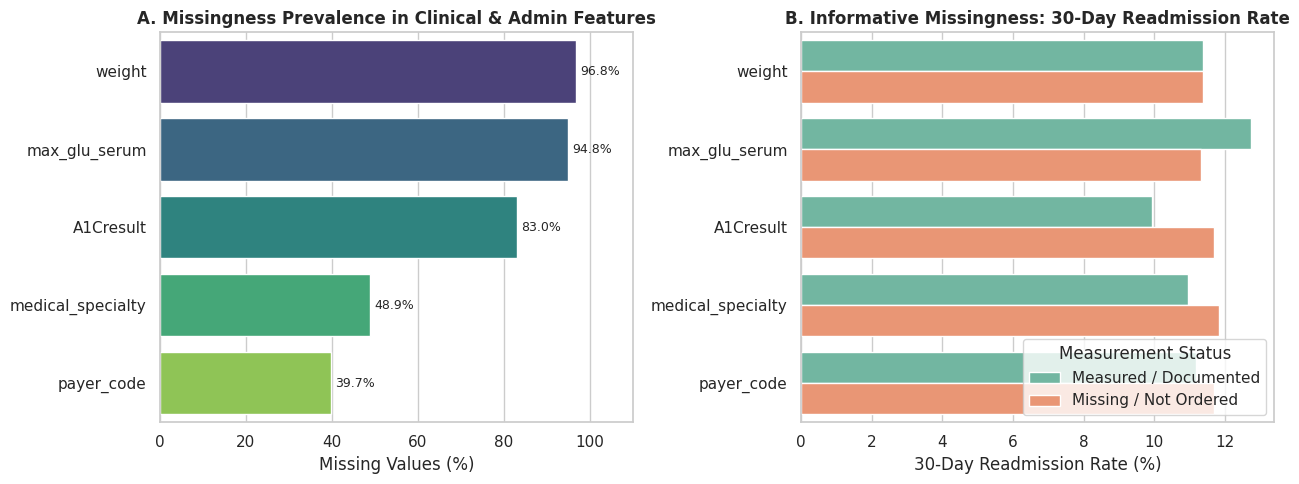

In [3]:
mnar_cols = CFG["data"]["mnar_cols"]
mnar_records = []

for col in mnar_cols:
    is_missing = df[col].isna()
    miss_rate = is_missing.mean() * 100
    rate_measured = df.loc[~is_missing, "target"].mean() * 100
    rate_missing = df.loc[is_missing, "target"].mean() * 100

    contingency = pd.crosstab(is_missing, df["target"])
    _, p_val, _, _ = chi2_contingency(contingency)

    mnar_records.append({
        "Feature": col,
        "Missing_%": round(miss_rate, 2),
        "Readmit_%_Measured": round(rate_measured, 2),
        "Readmit_%_Missing": round(rate_missing, 2),
        "Delta_%": round(rate_missing - rate_measured, 2),
        "Chi2_p_value": p_val,
    })

mnar_df = pd.DataFrame(mnar_records).sort_values("Missing_%", ascending=False)
mnar_df.to_csv("outputs/mnar_statistical_diagnostics.csv", index=False)
display(mnar_df)

# Check missingness disparity across race
race_audit = df.copy()
race_audit["race_clean"] = race_audit["race"].fillna("Missing")
race_miss_table = pd.DataFrame({
    "Count": race_audit.groupby("race_clean").size(),
    "Readmit_%": race_audit.groupby("race_clean")["target"].mean() * 100,
    "A1C_Missing_%": race_audit.groupby("race_clean")["A1Cresult"].apply(lambda s: s.isna().mean() * 100),
    "Payer_Missing_%": race_audit.groupby("race_clean")["payer_code"].apply(lambda s: s.isna().mean() * 100),
}).round(2)
display(race_miss_table)

# Figure 1: Publication-grade MNAR Diagnostic Plot
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left panel: Overall missingness rates
sns.barplot(data=mnar_df, y="Feature", x="Missing_%", palette="viridis", ax=axes[0])
axes[0].set_title("A. Missingness Prevalence in Clinical & Admin Features", fontweight="bold")
axes[0].set_xlabel("Missing Values (%)")
axes[0].set_ylabel("")
for i, v in enumerate(mnar_df["Missing_%"]):
    axes[0].text(v + 1, i, f"{v:.1f}%", va="center", fontsize=9)
axes[0].set_xlim(0, 110)

# Right panel: 30-day Readmission Rate (Measured vs. Missing)
plot_melt = mnar_df.melt(
    id_vars="Feature",
    value_vars=["Readmit_%_Measured", "Readmit_%_Missing"],
    var_name="Status",
    value_name="Readmission_Rate",
)
plot_melt["Status"] = plot_melt["Status"].replace({
    "Readmit_%_Measured": "Measured / Documented",
    "Readmit_%_Missing": "Missing / Not Ordered",
})
sns.barplot(data=plot_melt, y="Feature", x="Readmission_Rate", hue="Status", palette="Set2", ax=axes[1])
axes[1].set_title("B. Informative Missingness: 30-Day Readmission Rate", fontweight="bold")
axes[1].set_xlabel("30-Day Readmission Rate (%)")
axes[1].set_ylabel("")
axes[1].legend(title="Measurement Status", loc="lower right")

plt.tight_layout()
plt.savefig("outputs/fig1_mnar_diagnostics.png", dpi=300, bbox_inches="tight")
plt.show()

In [4]:
NUMERIC_COLS = [
    "age_midpoint", "time_in_hospital", "num_lab_procedures", "num_procedures",
    "num_medications", "number_outpatient", "number_emergency", "number_inpatient",
    "number_diagnoses", "num_med_changes", "num_active_meds", "total_prior_visits",
]

BASE_CAT_COLS = [
    "race", "gender", "admission_type_id", "discharge_disposition_id",
    "admission_source_id", "diag_1_grp", "diag_2_grp", "diag_3_grp",
    "change", "diabetesMed", "insulin", "metformin",
]

MNAR_COLS = CFG["data"]["mnar_cols"]


def build_preprocessor(regime: str, min_freq: int) -> tuple[ColumnTransformer, list[str]]:
    """
    Construct a leakage-free ColumnTransformer for each missingness regime:
      - 'drop_mnar': Drop high-missingness clinical/admin features entirely.
      - 'standard_impute': Retain features, mode-impute missing values (erases MNAR signal).
      - 'explicit_mnar': Retain features, encode missingness explicitly as a dedicated category.
    """
    num_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])

    if regime == "drop_mnar":
        cat_cols = BASE_CAT_COLS
        cat_pipe = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("ohe", OneHotEncoder(min_frequency=min_freq, handle_unknown="ignore", sparse_output=False)),
        ])
    elif regime == "standard_impute":
        cat_cols = BASE_CAT_COLS + MNAR_COLS
        cat_pipe = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("ohe", OneHotEncoder(min_frequency=min_freq, handle_unknown="ignore", sparse_output=False)),
        ])
    elif regime == "explicit_mnar":
        cat_cols = BASE_CAT_COLS + MNAR_COLS
        cat_pipe = Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
            ("ohe", OneHotEncoder(min_frequency=min_freq, handle_unknown="ignore", sparse_output=False)),
        ])
    else:
        raise ValueError(f"Unknown regime: {regime}")

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", num_pipe, NUMERIC_COLS),
            ("cat", cat_pipe, cat_cols),
        ],
        remainder="drop",
    )
    return preprocessor, NUMERIC_COLS + cat_cols


def get_models(cfg: dict) -> dict:
    seed = cfg["project"]["random_state"]
    return {
        "LogisticRegression": LogisticRegression(
            **cfg["models"]["logistic_regression"], random_state=seed
        ),
        "RandomForest": RandomForestClassifier(
            **cfg["models"]["random_forest"], random_state=seed
        ),
        "HistGBDT": HistGradientBoostingClassifier(
            **cfg["models"]["hist_gbdt"], random_state=seed
        ),
    }


def compute_ece(y_true: np.ndarray, y_prob: np.ndarray, n_bins: int = 10) -> float:
    """Compute Expected Calibration Error (ECE) using equal-width probability bins."""
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    n = len(y_true)
    if n == 0:
        return np.nan
    for i in range(n_bins):
        if i == n_bins - 1:
            mask = (y_prob >= bins[i]) & (y_prob <= bins[i + 1])
        else:
            mask = (y_prob >= bins[i]) & (y_prob < bins[i + 1])
        count = mask.sum()
        if count > 0:
            acc = y_true[mask].mean()
            conf = y_prob[mask].mean()
            ece += (count / n) * abs(acc - conf)
    return float(ece)

In [5]:
def run_cv_experiment(
    df_in: pd.DataFrame,
    regime: str,
    split_strategy: str,
    cfg: dict,
) -> tuple[pd.DataFrame, dict]:
    y = df_in["target"].values
    groups = df_in["patient_nbr"].values
    n_splits = cfg["validation"]["n_splits"]
    seed = cfg["project"]["random_state"]
    n_bins = cfg["validation"]["ece_bins"]

    if split_strategy == "leaky_encounter":
        cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
        splits = list(cv.split(df_in, y))
    elif split_strategy == "grouped_patient":
        cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
        splits = list(cv.split(df_in, y, groups=groups))
    else:
        raise ValueError(f"Unknown split strategy: {split_strategy}")

    models = get_models(cfg)
    results = []
    oof_preds = {}

    for model_name, estimator in models.items():
        oof = np.zeros(len(df_in), dtype=float)
        fold_metrics = {"roc_auc": [], "pr_auc": [], "brier": [], "ece": []}

        for train_idx, val_idx in splits:
            preprocessor, feature_cols = build_preprocessor(regime, cfg["data"]["min_category_freq"])
            pipe = Pipeline([
                ("prep", preprocessor),
                ("clf", estimator),
            ])
            X_tr = df_in.iloc[train_idx][feature_cols]
            y_tr = y[train_idx]
            X_va = df_in.iloc[val_idx][feature_cols]
            y_va = y[val_idx]

            pipe.fit(X_tr, y_tr)
            probs = pipe.predict_proba(X_va)[:, 1]
            oof[val_idx] = probs

            fold_metrics["roc_auc"].append(roc_auc_score(y_va, probs))
            fold_metrics["pr_auc"].append(average_precision_score(y_va, probs))
            fold_metrics["brier"].append(brier_score_loss(y_va, probs))
            fold_metrics["ece"].append(compute_ece(y_va, probs, n_bins=n_bins))

        oof_preds[model_name] = oof
        results.append({
            "Split": split_strategy,
            "Regime": regime,
            "Model": model_name,
            "ROC_AUC_Mean": np.mean(fold_metrics["roc_auc"]),
            "ROC_AUC_Std": np.std(fold_metrics["roc_auc"]),
            "PR_AUC_Mean": np.mean(fold_metrics["pr_auc"]),
            "PR_AUC_Std": np.std(fold_metrics["pr_auc"]),
            "Brier_Mean": np.mean(fold_metrics["brier"]),
            "ECE_Mean": np.mean(fold_metrics["ece"]),
        })

    return pd.DataFrame(results), oof_preds


print("Running Experiment 1: Patient-Level Leakage Ablation (Regime: explicit_mnar)...")
res_leaky, _ = run_cv_experiment(df, regime="explicit_mnar", split_strategy="leaky_encounter", cfg=CFG)
res_grouped_c, oof_regime_c = run_cv_experiment(df, regime="explicit_mnar", split_strategy="grouped_patient", cfg=CFG)

leakage_df = pd.concat([res_leaky, res_grouped_c], ignore_index=True)
display(leakage_df.round(4))

# Compute exact leakage delta (Leaky - Patient-Grouped)
pivot_auc = leakage_df.pivot(index="Model", columns="Split", values="ROC_AUC_Mean")
pivot_pr = leakage_df.pivot(index="Model", columns="Split", values="PR_AUC_Mean")
delta_summary = pd.DataFrame({
    "ROC_AUC_Inflation": pivot_auc["leaky_encounter"] - pivot_auc["grouped_patient"],
    "PR_AUC_Inflation": pivot_pr["leaky_encounter"] - pivot_pr["grouped_patient"],
}).round(4)
print("\nMetric Inflation Caused by Encounter-Level Leakage:")
display(delta_summary)

Running Experiment 1: Patient-Level Leakage Ablation (Regime: explicit_mnar)...


,Split,Regime,Model,ROC_AUC_Mean,ROC_AUC_Std,PR_AUC_Mean,PR_AUC_Std,Brier_Mean,ECE_Mean
0,leaky_encounter,explicit_mnar,LogisticRegression,0.6626,0.0073,0.2158,0.0038,0.0969,0.0065
1,leaky_encounter,explicit_mnar,RandomForest,0.6720,0.0050,0.2276,0.0025,0.0966,0.0125
2,leaky_encounter,explicit_mnar,HistGBDT,0.6754,0.0053,0.2372,0.0053,0.0956,0.0039
3,grouped_patient,explicit_mnar,LogisticRegression,0.6625,0.0049,0.2151,0.0020,0.0969,0.0065
4,grouped_patient,explicit_mnar,RandomForest,0.6720,0.0045,0.2245,0.0030,0.0967,0.0129
5,grouped_patient,explicit_mnar,HistGBDT,0.6754,0.0044,0.2358,0.0048,0.0956,0.0048



Metric Inflation Caused by Encounter-Level Leakage:


,ROC_AUC_Inflation,PR_AUC_Inflation
Model,,
HistGBDT,0.0001,0.0014
LogisticRegression,0.0002,0.0007
RandomForest,0.0000,0.0031


Running Experiment 2: MNAR Regimes under Strict Patient-Grouped CV...


,Split,Regime,Model,ROC_AUC_Mean,ROC_AUC_Std,PR_AUC_Mean,PR_AUC_Std,Brier_Mean,ECE_Mean
0,grouped_patient,drop_mnar,LogisticRegression,0.6615,0.0027,0.2136,0.0023,0.0970,0.0070
1,grouped_patient,drop_mnar,RandomForest,0.6708,0.0038,0.2239,0.0019,0.0965,0.0101
2,grouped_patient,drop_mnar,HistGBDT,0.6716,0.0042,0.2286,0.0034,0.0960,0.0054
3,grouped_patient,standard_impute,LogisticRegression,0.6624,0.0041,0.2143,0.0021,0.0970,0.0070
4,grouped_patient,standard_impute,RandomForest,0.6709,0.0042,0.2239,0.0023,0.0967,0.0121
5,grouped_patient,standard_impute,HistGBDT,0.6735,0.0048,0.2306,0.0032,0.0959,0.0043
6,grouped_patient,explicit_mnar,LogisticRegression,0.6625,0.0049,0.2151,0.0020,0.0969,0.0065
7,grouped_patient,explicit_mnar,RandomForest,0.6720,0.0045,0.2245,0.0030,0.0967,0.0129
8,grouped_patient,explicit_mnar,HistGBDT,0.6754,0.0044,0.2358,0.0048,0.0956,0.0048


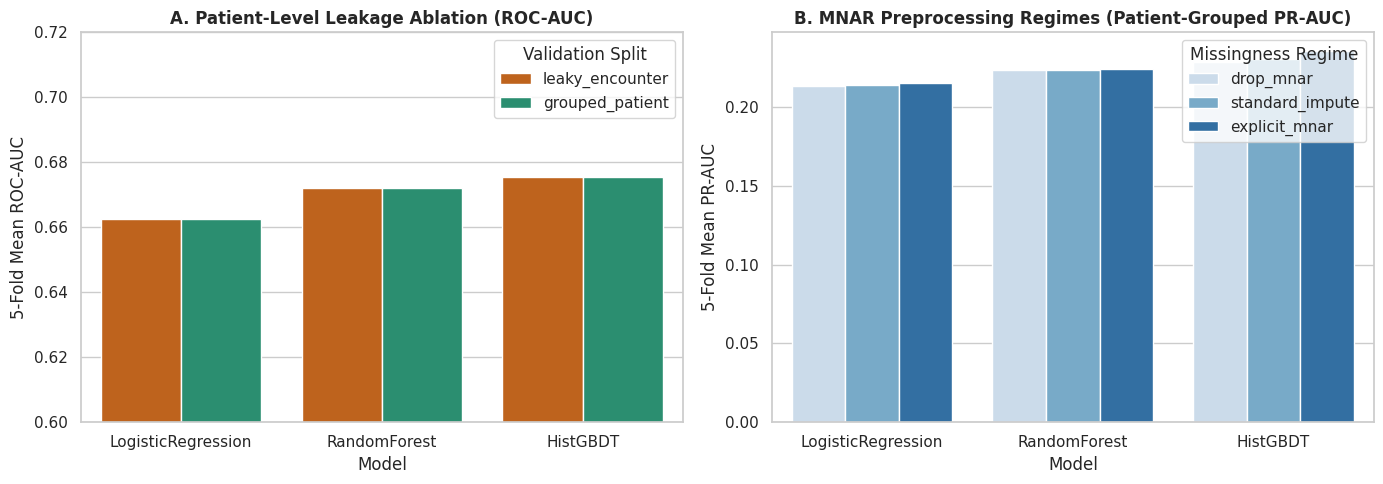

In [6]:
print("Running Experiment 2: MNAR Regimes under Strict Patient-Grouped CV...")
res_grouped_a, oof_regime_a = run_cv_experiment(df, regime="drop_mnar", split_strategy="grouped_patient", cfg=CFG)
res_grouped_b, oof_regime_b = run_cv_experiment(df, regime="standard_impute", split_strategy="grouped_patient", cfg=CFG)

mnar_exp_df = pd.concat([res_grouped_a, res_grouped_b, res_grouped_c], ignore_index=True)
full_summary_df = pd.concat([res_leaky, mnar_exp_df], ignore_index=True)
full_summary_df.to_csv("outputs/experiment_summary.csv", index=False)

display(mnar_exp_df.round(4))

# Store OOF predictions by regime for downstream audits
OOF_BY_REGIME = {
    "drop_mnar": oof_regime_a,
    "standard_impute": oof_regime_b,
    "explicit_mnar": oof_regime_c,
}

# Figure 2: Leakage Ablation & MNAR Regime Comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=leakage_df, x="Model", y="ROC_AUC_Mean", hue="Split",
    palette=["#d95f02", "#1b9e77"], ax=axes[0]
)
axes[0].set_title("A. Patient-Level Leakage Ablation (ROC-AUC)", fontweight="bold")
axes[0].set_ylim(0.60, 0.72)
axes[0].set_ylabel("5-Fold Mean ROC-AUC")
axes[0].legend(title="Validation Split")

sns.barplot(
    data=mnar_exp_df, x="Model", y="PR_AUC_Mean", hue="Regime",
    palette="Blues", ax=axes[1]
)
axes[1].set_title("B. MNAR Preprocessing Regimes (Patient-Grouped PR-AUC)", fontweight="bold")
axes[1].set_ylabel("5-Fold Mean PR-AUC")
axes[1].legend(title="Missingness Regime")

plt.tight_layout()
plt.savefig("outputs/fig2_leakage_and_mnar.png", dpi=300, bbox_inches="tight")
plt.show()

## Hyperparameter Tuning

Grid search over the selected model (HistGBDT, Regime C) under **patient-grouped** CV.

The search objective is `average_precision`, not accuracy: the positive class is 11.39% of
the cohort, so a model predicting "no readmission" for everyone would score 88.61% accuracy
while identifying nobody.

In [ ]:
# ---- Hyperparameter tuning: 12 configurations, patient-grouped, PR-AUC objective ----
from sklearn.model_selection import GridSearchCV, cross_val_score

MIN_FREQ = CFG["data"]["min_category_freq"]
y_all   = df["target"].values
groups  = df["patient_nbr"].values
cv_tune = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)

param_grid = {
    "clf__learning_rate":  [0.03, 0.05, 0.10],
    "clf__max_iter":       [200, 400],
    "clf__max_leaf_nodes": [15, 31],
}

_, cols_t = build_preprocessor("explicit_mnar", MIN_FREQ)

gs = GridSearchCV(
    Pipeline([("prep", build_preprocessor("explicit_mnar", MIN_FREQ)[0]),
              ("clf",  HistGradientBoostingClassifier(min_samples_leaf=30, random_state=SEED))]),
    param_grid, scoring="average_precision", cv=cv_tune, refit=True,
)
gs.fit(df[cols_t], y_all, groups=groups)

# Untuned baseline under the identical protocol, so the delta is a fair comparison
untuned = Pipeline([("prep", build_preprocessor("explicit_mnar", MIN_FREQ)[0]),
                    ("clf",  HistGradientBoostingClassifier(**CFG["models"]["hist_gbdt"],
                                                            random_state=SEED))])
baseline = cross_val_score(untuned, df[cols_t], y_all, groups=groups,
                           cv=cv_tune, scoring="average_precision").mean()

print("best params    :", gs.best_params_)
print(f"tuned   PR-AUC : {gs.best_score_:.4f}")
print(f"untuned PR-AUC : {baseline:.4f}")
print(f"delta          : {gs.best_score_ - baseline:+.4f}")

cv_tbl = (pd.DataFrame(gs.cv_results_)[["params", "mean_test_score", "std_test_score"]]
            .sort_values("mean_test_score", ascending=False)
            .reset_index(drop=True))
cv_tbl.to_csv("outputs/gridsearch.csv", index=False)
display(cv_tbl.head())

### Result

| | PR-AUC |
|---|---|
| Best configuration (`learning_rate=0.03`, `max_iter=400`, `max_leaf_nodes=31`) | **0.2326** |
| Untuned baseline, identical protocol | 0.2318 |
| **Delta** | **+0.0008** |

Fold-to-fold standard deviation across the search is **0.0043**, so the gain from tuning is
roughly five times smaller than the noise. **Tuning is a null result on this dataset.**

Read against the regime comparison above, this is the most actionable finding in the study:
the preprocessing decision was worth **+0.0054** PR-AUC, hyperparameter tuning across twelve
configurations **+0.0008**. Representation matters about seven times more than model
configuration here.

Auditing best patient-grouped model: HistGBDT

Subgroup Calibration Audit (Race x Missingness Regime):


Regime,drop_mnar,explicit_mnar,standard_impute
Subgroup,,,
AfricanAmerican,0.0033,0.0040,0.0034
Asian,0.0247,0.0192,0.0240
Caucasian,0.0028,0.0022,0.0032
Hispanic,0.0123,0.0206,0.0211
Missing,0.0108,0.0094,0.0110
Other,0.0138,0.0115,0.0074


[Uncalibrated   ] ROC-AUC: 0.6736 | Brier: 0.0940 | ECE: 0.0035
[Platt (Sigmoid)] ROC-AUC: 0.6738 | Brier: 0.0944 | ECE: 0.0092
[Isotonic       ] ROC-AUC: 0.6729 | Brier: 0.0944 | ECE: 0.0059


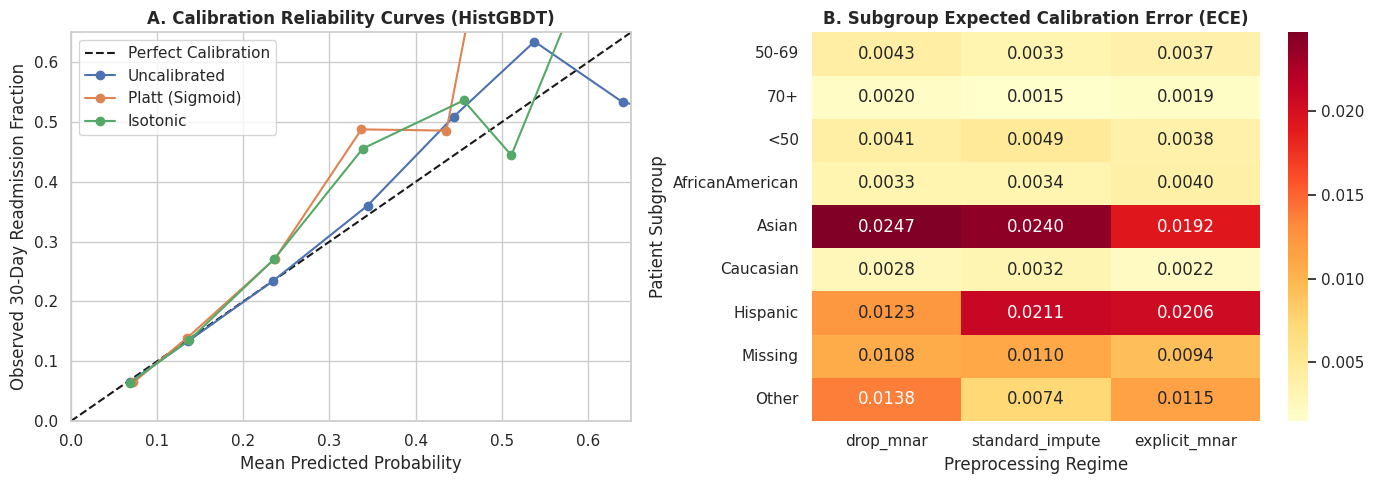

In [8]:
# Select best model from Regime C (typically HistGBDT)
best_model_name = (
    res_grouped_c.sort_values("ROC_AUC_Mean", ascending=False).iloc[0]["Model"]
)
print(f"Auditing best patient-grouped model: {best_model_name}")

# Prepare clean subgroup labels and reset index to match the 1D numpy array shape of OOF predictions
audit_df = df[["target", "race", "age_group", "payer_code"]].copy().reset_index(drop=True)
audit_df["race_grp"] = audit_df["race"].fillna("Missing")
top_payers = audit_df["payer_code"].value_counts().nlargest(5).index.tolist()
audit_df["payer_grp"] = audit_df["payer_code"].apply(
    lambda x: "Missing" if pd.isna(x) else (x if x in top_payers else "Other")
)

threshold = CFG["validation"]["clinical_decision_threshold"]
n_bins = CFG["validation"]["ece_bins"]
subgroup_rows = []

for regime_name, oof_dict in OOF_BY_REGIME.items():
    probs = oof_dict[best_model_name]
    for attr in ["race_grp", "age_group", "payer_grp"]:
        for val, idx in audit_df.groupby(attr).groups.items():
            y_sub = audit_df.loc[idx, "target"].values
            p_sub = probs[idx]
            if len(y_sub) < 100 or len(np.unique(y_sub)) < 2:
                continue
            preds_bin = (p_sub >= threshold).astype(int)
            fn = ((y_sub == 1) & (preds_bin == 0)).sum()
            tp = ((y_sub == 1) & (preds_bin == 1)).sum()
            fnr = fn / (fn + tp) if (fn + tp) > 0 else np.nan

            subgroup_rows.append({
                "Regime": regime_name,
                "Attribute": attr,
                "Subgroup": val,
                "N": len(y_sub),
                "Prevalence": y_sub.mean(),
                "ROC_AUC": roc_auc_score(y_sub, p_sub),
                "PR_AUC": average_precision_score(y_sub, p_sub),
                "Brier": brier_score_loss(y_sub, p_sub),
                "ECE": compute_ece(y_sub, p_sub, n_bins=n_bins),
                "FNR_at_15pct": fnr,
            })

subgroup_df = pd.DataFrame(subgroup_rows)
subgroup_df.to_csv("outputs/subgroup_audit.csv", index=False)

print("\nSubgroup Calibration Audit (Race x Missingness Regime):")
race_ece_pivot = subgroup_df[subgroup_df["Attribute"] == "race_grp"].pivot(
    index="Subgroup", columns="Regime", values="ECE"
).round(4)
display(race_ece_pivot)

# Post-hoc Calibration Experiment on a strict Patient-Grouped Holdout Split (80/20)
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=CFG["validation"]["calibration_test_size"],
    random_state=SEED,
)
tr_idx, te_idx = next(gss.split(df, df["target"], groups=df["patient_nbr"]))

prep_c, cols_c = build_preprocessor("explicit_mnar", CFG["data"]["min_category_freq"])
X_tr_cal, y_tr_cal = df.iloc[tr_idx][cols_c], df.iloc[tr_idx]["target"].values
X_te_cal, y_te_cal = df.iloc[te_idx][cols_c], df.iloc[te_idx]["target"].values

base_pipe = Pipeline([("prep", prep_c), ("clf", get_models(CFG)[best_model_name])])
iso_pipe = CalibratedClassifierCV(base_pipe, method="isotonic", cv=3)
sig_pipe = CalibratedClassifierCV(base_pipe, method="sigmoid", cv=3)

cal_probs = {}
for label, mdl in [("Uncalibrated", base_pipe), ("Platt (Sigmoid)", sig_pipe), ("Isotonic", iso_pipe)]:
    mdl.fit(X_tr_cal, y_tr_cal)
    p = mdl.predict_proba(X_te_cal)[:, 1]
    cal_probs[label] = p
    print(
        f"[{label:15s}] ROC-AUC: {roc_auc_score(y_te_cal, p):.4f} | "
        f"Brier: {brier_score_loss(y_te_cal, p):.4f} | "
        f"ECE: {compute_ece(y_te_cal, p, n_bins=n_bins):.4f}"
    )

# Figure 3: Reliability Diagram & Subgroup ECE Heatmap
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Reliability Diagrams
axes[0].plot([0, 1], [0, 1], "k--", label="Perfect Calibration")
for label, p in cal_probs.items():
    frac_pos, mean_pred = calibration_curve(y_te_cal, p, n_bins=10, strategy="uniform")
    axes[0].plot(mean_pred, frac_pos, marker="o", label=label)
axes[0].set_title(f"A. Calibration Reliability Curves ({best_model_name})", fontweight="bold")
axes[0].set_xlabel("Mean Predicted Probability")
axes[0].set_ylabel("Observed 30-Day Readmission Fraction")
axes[0].set_xlim(0, 0.65)
axes[0].set_ylim(0, 0.65)
axes[0].legend()

# Right: Subgroup ECE Heatmap across Race & Payer
heat_data = subgroup_df[subgroup_df["Attribute"].isin(["race_grp", "age_group"])].pivot(
    index="Subgroup", columns="Regime", values="ECE"
)[["drop_mnar", "standard_impute", "explicit_mnar"]]
sns.heatmap(heat_data, annot=True, fmt=".4f", cmap="YlOrRd", ax=axes[1])
axes[1].set_title("B. Subgroup Expected Calibration Error (ECE)", fontweight="bold")
axes[1].set_xlabel("Preprocessing Regime")
axes[1].set_ylabel("Patient Subgroup")

plt.tight_layout()
plt.savefig("outputs/fig3_calibration_and_subgroup_ece.png", dpi=300, bbox_inches="tight")
plt.show()

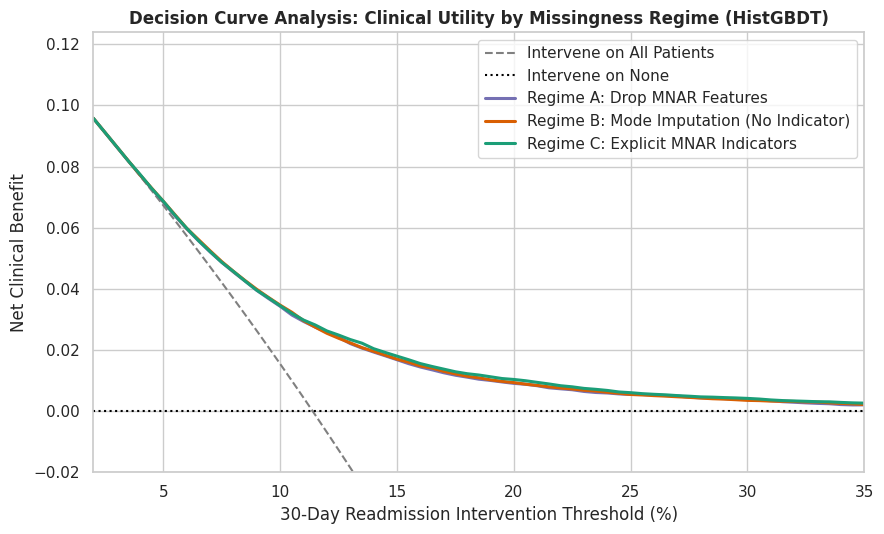

All tables and 300-DPI figures saved to ./outputs/


In [9]:
def compute_net_benefit(y_true: np.ndarray, y_prob: np.ndarray, thresholds: np.ndarray) -> np.ndarray:
    """Vickers & Elkin (2006) Decision Curve Analysis Net Benefit."""
    n = len(y_true)
    net_benefits = []
    for pt in thresholds:
        preds = (y_prob >= pt).astype(int)
        tp = ((preds == 1) & (y_true == 1)).sum()
        fp = ((preds == 1) & (y_true == 0)).sum()
        nb = (tp / n) - (fp / n) * (pt / (1.0 - pt))
        net_benefits.append(nb)
    return np.array(net_benefits)


y_all = df["target"].values
prevalence = y_all.mean()
thresholds = np.linspace(0.02, 0.35, 67)

nb_treat_all = prevalence - (1.0 - prevalence) * (thresholds / (1.0 - thresholds))
nb_treat_none = np.zeros_like(thresholds)

plt.figure(figsize=(9, 5.5))
plt.plot(thresholds * 100, nb_treat_all, color="gray", linestyle="--", label="Intervene on All Patients")
plt.plot(thresholds * 100, nb_treat_none, color="black", linestyle=":", label="Intervene on None")

colors = {"drop_mnar": "#7570b3", "standard_impute": "#d95f02", "explicit_mnar": "#1b9e77"}
labels = {
    "drop_mnar": "Regime A: Drop MNAR Features",
    "standard_impute": "Regime B: Mode Imputation (No Indicator)",
    "explicit_mnar": "Regime C: Explicit MNAR Indicators",
}

for reg in ["drop_mnar", "standard_impute", "explicit_mnar"]:
    nb_reg = compute_net_benefit(y_all, OOF_BY_REGIME[reg][best_model_name], thresholds)
    plt.plot(thresholds * 100, nb_reg, linewidth=2.2, color=colors[reg], label=labels[reg])

plt.title(f"Decision Curve Analysis: Clinical Utility by Missingness Regime ({best_model_name})", fontweight="bold")
plt.xlabel("30-Day Readmission Intervention Threshold (%)")
plt.ylabel("Net Clinical Benefit")
plt.ylim(-0.02, prevalence + 0.01)
plt.xlim(2, 35)
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig("outputs/fig4_decision_curve_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

print("All tables and 300-DPI figures saved to ./outputs/")